In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load dataset (Ensure 'Telecom_Tower_Failure_Dataset_10000-1.csv' is uploaded in Colab)
df = pd.read_csv("Telecom_Tower_Failure_Dataset_10000-1.csv")

print("--- Initial Dataset Info ---")
display(df.head())
print("Shape:", df.shape)



--- Initial Dataset Info ---


,Tower_ID,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,Failure_Within_48Hrs
0,1,35.6,50.91,2962,56,2838,52,2612,4,0
1,2,43.9,53.33,736,69,3139,36,3427,6,0
2,3,29.0,51.01,2335,50,3117,81,4254,11,1
3,4,39.0,45.62,2808,88,3367,92,1575,7,0
4,5,56.8,51.29,2590,100,1040,25,1336,4,1


Shape: (10000, 10)


In [3]:
# 2. Handle missing numerical values using median imputation
numeric_columns = df.select_dtypes(include=np.number).columns
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# 3. Feature Engineering
# Feature 1: High Temperature indicator
df["High_Temperature"] = np.where(df["Temperature_C"] > 60, 1, 0)

# Feature 2: Low Battery indicator
df["Low_Battery"] = np.where(df["Battery_Voltage"] < 45, 1, 0)

# Feature 3: Power-Traffic Ratio
df["Power_Traffic_Ratio"] = df["Power_Consumption_W"] / (df["Traffic_Load"] + 0.01)

# Feature 4: Tower Age Category (Binning)
df["Tower_Age_Category"] = pd.cut(
    df["Tower_Age_Years"],
    bins=[0, 3, 7, np.inf],
    labels=["New", "Medium", "Old"]
)



In [4]:
# 4. One-Hot Encoding for categorical age features
df = pd.get_dummies(df, columns=["Tower_Age_Category"], dtype=int)

# 5. Drop unnecessary identifier column
df = df.drop(columns=["Tower_ID"])

# 6. Separate Features (X) and Target (y)
X = df.drop(columns=["Failure_Within_48Hrs"])
y = df.Failure_Within_48Hrs

print("\n--- Feature Engineering Completed ---")
print("Number of features (X columns):", X.shape[1])
print("Number of records:", X.shape[0])




--- Feature Engineering Completed ---
Number of features (X columns): 14
Number of records: 10000



Target Distribution:
Failure_Within_48Hrs
1    6613
0    3387
Name: count, dtype: int64


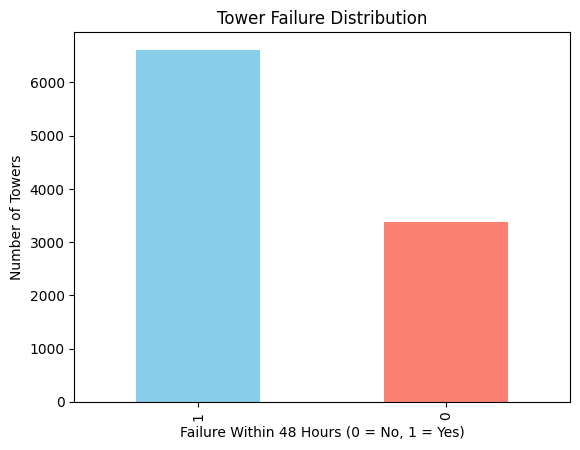


Processed dataset successfully saved as 'telecom_tower_feature_engineered.csv'!


In [5]:
# 7. Check Target Distribution
print("\nTarget Distribution:")
print(y.value_counts())

# Visualize Target Distribution
y.value_counts().plot(kind="bar", color=["skyblue", "salmon"])
plt.xlabel("Failure Within 48 Hours (0 = No, 1 = Yes)")
plt.ylabel("Number of Towers")
plt.title("Tower Failure Distribution")
plt.show()

# 8. Save Processed Dataset
output_filename = "telecom_tower_feature_engineered.csv"
df.to_csv(output_filename, index=False)
print(f"\nProcessed dataset successfully saved as '{output_filename}'!")